# Method 1 — OCR + Regex Baseline

**Issue #3.** A rule-based baseline with no machine learning. The BERT and LayoutLM models are compared against it.

- **Data:** `darentang/sroie` (OCR words, boxes, tags; 347 test receipts) joined by receipt key with `jsdnrs/ICDAR2019-SROIE` (images + official answers). See `src/data.py`.
- **OCR:** SROIE already provides OCR words and their bounding boxes, so we use the dataset's OCR output.
- **Lines:** words are grouped into text lines using their vertical position.
- **Rules:** one hand-written rule set per field (code in `src/regex_baseline.py`):

| Field | Rule |
|---|---|
| date | First match of a date regex (`25/12/2018`, `12-01-19`, `2018-12-25`, `25 Dec 2018`) |
| total | Amount on a `TOTAL` line (not subtotal / GST / qty). Prefer the line after "Rounding" or "Total Incl. GST / Rounded / Nett", apply rounding adjustments. Fallback: largest amount |
| company | First line near the top with a company keyword (`SDN BHD`, `ENTERPRISE`, `TRADING`, …), with store codes / registration numbers removed |
| address | Lines after the company up to the 5-digit postcode line, plus a short state-name line |

Rules were tuned on the **train** split only; the final score is on the **test** split.

In [1]:
# Install the libraries Colab doesn't have (datasets<3 as pinned in requirements.txt).
!pip install -q transformers "datasets<3" seqeval

In [2]:
# Why: the shared code in src/ (data loading, evaluation) is imported by every notebook, so all
# methods load and score the data in exactly the same way.
# Make `src/` importable. In a fresh Colab runtime the repo isn't there yet, so clone it.
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/chundawat-h/Receipt-Invoice-Information-Extraction.git"
if Path("../src").is_dir():            # running from notebooks/ inside the repo
    ROOT = Path("..")
elif Path("src").is_dir():
    ROOT = Path(".")
else:                                  # Colab (clone once; re-running the cell reuses it)
    ROOT = Path("Receipt-Invoice-Information-Extraction")
    if not ROOT.is_dir():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
sys.path.insert(0, str(ROOT.resolve()))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

In [3]:
# Test receipts plus the rules from src/regex_baseline.py. The rules read the dataset's OCR words and
# boxes, the same input the models get.
from src.data import load_sroie, load_images
from src.evaluate import get_gold, get_official_gold, evaluate, normalize, save_preds
from src.regex_baseline import group_lines, extract_fields, predict

# Word-tagged SROIE (darentang/sroie): train 626 / test 347, with a `key` column.
ds = load_sroie()
test = ds["test"]
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 626
    })
    test: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 347
    })
})

## 1. A receipt: image, OCR boxes and text lines

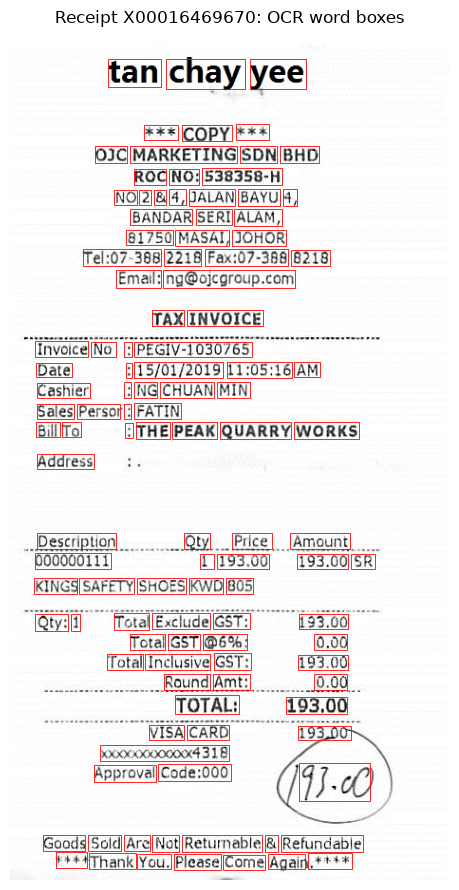

In [4]:
# One test receipt with its OCR word boxes: the input the rules work from.
import matplotlib.pyplot as plt
import matplotlib.patches as patches

example = test[0]
key = example["key"]
image = load_images("test", [key])[key]  # from jsdnrs/ICDAR2019-SROIE
W, H = image.size

fig, ax = plt.subplots(figsize=(5, 9))
ax.imshow(image)
for x0, y0, x1, y1 in example["bboxes"]:  # boxes are scaled 0-1000
    ax.add_patch(patches.Rectangle((x0 * W / 1000, y0 * H / 1000), (x1 - x0) * W / 1000, (y1 - y0) * H / 1000,
                                   fill=False, edgecolor="red", linewidth=0.6))
ax.set_title(f"Receipt {key}: OCR word boxes"); ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
# The rules work on text lines, so the words are first grouped into lines by their vertical position.
lines = group_lines(example["words"], example["bboxes"])
print(f"{len(example['words'])} words -> {len(lines)} lines\n")
print("\n".join(lines[:20]))

114 words -> 29 lines

tan chay yee
*** COPY ***
OJC MARKETING SDN BHD
ROC NO: 538358-H
NO 2 & 4, JALAN BAYU 4,
BANDAR SERI ALAM,
81750 MASAI, JOHOR
Tel:07-388 2218 Fax:07-388 8218
Email: ng@ojcgroup.com
TAX INVOICE
Invoice No : PEGIV-1030765
Date : 15/01/2019 11:05:16 AM
Cashier : NG CHUAN MIN
Sales Persor : FATIN
Bill To : THE PEAK QUARRY WORKS
Address
Description Qty Price Amount
000000111 1 193.00 193.00 SR
KINGS SAFETY SHOES KWD 805
Qty: 1 Total Exclude GST: 193.00


## 2. Rules applied to one receipt

In [6]:
# The rules applied to one receipt, next to both gold standards.
gold_test = get_gold(test)                                         # main gold (darentang tags)
official_gold = get_official_gold("test", keys=test["key"])  # official ICDAR answers (~1 min)

print("Predicted:", extract_fields(example["words"], example["bboxes"]))
print("Gold:     ", gold_test[key])
print("Official: ", official_gold[key])

Predicted: {'company': '*** COPY *** OJC MARKETING SDN BHD', 'date': '15/01/2019', 'address': 'NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR', 'total': '193.00'}
Gold:      {'company': 'OJC MARKETING SDN BHD', 'date': '15/01/2019', 'address': 'NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, 81750 MASAI, JOHOR', 'total': '193.00'}
Official:  {'company': 'OJC MARKETING SDN BHD', 'date': '15/01/2019', 'address': 'NO 2 & 4, JALAN BAYU 4, BANDAR SERI ALAM, B1750 MASAI, JOHOR', 'total': '193.00'}


## 3. Predict on the test set and save (keyed by receipt key)

In [7]:
# Predict all four fields for every test receipt and save them in the shared format (keyed by receipt
# key), so notebook 05 can compare all methods.
regex_preds = predict(test)
save_preds(regex_preds, RESULTS / "regex_preds.json")
print(f"Saved predictions for {len(regex_preds)} test receipts -> {RESULTS / 'regex_preds.json'}")
print("Example keys:", list(regex_preds)[:3])

Saved predictions for 347 test receipts -> ..\results\regex_preds.json
Example keys: ['X00016469670', 'X00016469671', 'X51005200931']


## 4. Evaluation (field-level exact match, `src/evaluate.py`)

- **Main score:** against gold rebuilt from the darentang word tags.
- **Second score:** against the official ICDAR answers. Even a perfect tagger can't reach 100 % here because of OCR noise, so the ceiling is shown too.

Note: about 2.6 % of gold DATE spans include extra words such as "Date:" or a time. The regex returns only the date itself, so it loses these cases even when it found the right date.

In [8]:
# Scores: train (the rules were tuned there, so optimistic), test vs the tagged-word gold (main) and vs
# the official answers (second), plus the perfect-tagger ceiling for reference.
print("TRAIN, main gold (rules were tuned here)")
print(evaluate(predict(ds["train"]), get_gold(ds["train"])).to_string())

print("\nTEST, main gold")
test_scores = evaluate(regex_preds, gold_test)
test_scores.to_csv(RESULTS / "regex_scores.csv")
print(test_scores.to_string())

print("\nTEST, official ICDAR answers")
official_scores = evaluate(regex_preds, official_gold)
official_scores.to_csv(RESULTS / "regex_scores_official.csv")
print(official_scores.to_string())

print("\nPerfect-tagger ceiling vs official answers (OCR noise)")
print(evaluate(gold_test, official_gold)[["f1"]].T.to_string())

TRAIN, main gold (rules were tuned here)


           precision  recall     f1  correct  predicted  gold
field                                                        
company        71.57   71.57  71.57      448        626   626
date           97.08   95.69  96.38      599        617   626
address        61.82   61.92  61.87      387        626   625
total          76.84   76.84  76.84      481        626   626
macro_avg      76.83   76.50  76.66     <NA>       <NA>  <NA>

TEST, main gold
           precision  recall     f1  correct  predicted  gold
field                                                        
company        68.30   68.30  68.30      237        347   347
date           96.49   95.10  95.79      330        342   347
address        59.94   59.94  59.94      208        347   347
total          75.22   75.22  75.22      261        347   347
macro_avg      74.99   74.64  74.81     <NA>       <NA>  <NA>

TEST, official ICDAR answers
           precision  recall     f1  correct  predicted  gold
field                  

field  company   date  address  total  macro_avg
f1        80.4  96.25    58.21  96.25      82.78


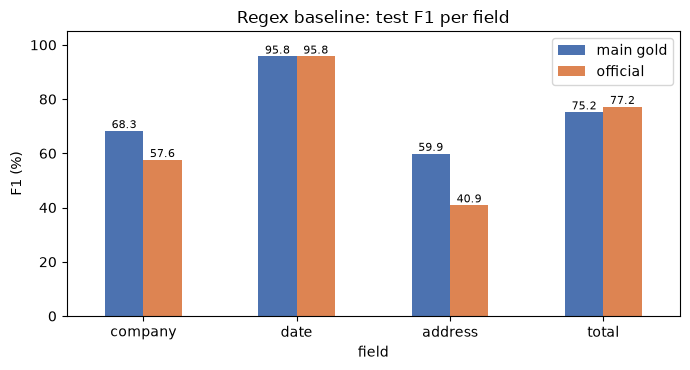

In [9]:
# F1 per field against both golds (results/regex_f1.png).
import pandas as pd

f1 = pd.DataFrame({"main gold": test_scores["f1"], "official": official_scores["f1"]}).drop("macro_avg")
ax = f1.plot.bar(rot=0, figsize=(7, 3.8), color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 105); ax.set_ylabel("F1 (%)"); ax.set_title("Regex baseline: test F1 per field")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height() + 1), ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "regex_f1.png", dpi=150); plt.show()

## 5. Where the rules fail (examples for the report)

In [10]:
# The first 3 failures per field: examples for the report's error discussion.
for field in ["company", "address", "total", "date"]:
    print(f"=== {field} ===")
    shown = 0
    for k, gold in gold_test.items():
        pred = regex_preds[k][field]
        if normalize(pred, field) != normalize(gold[field], field):
            print(f"  [{k}] PRED: {pred!r}\n                GOLD: {gold[field]!r}")
            shown += 1
            if shown == 3:
                break
    print()

=== company ===
  [X00016469670] PRED: '*** COPY *** OJC MARKETING SDN BHD'
                GOLD: 'OJC MARKETING SDN BHD'
  [X00016469671] PRED: 'tan chay yee OJC MARKETING SDN BHD'
                GOLD: 'OJC MARKETING SDN BHD'
  [X51005230605] PRED: 'ALSERKAM ENTERPRISE'
                GOLD: 'PETRON BKT LANJAN SB'

=== address ===
  [X51005230616] PRED: "formerly known as Golden Arches Restaurants Sdn Bhd Licensee of McDonald's Level 6, Bangunan TH, Damansara Uptown3"
                GOLD: 'Level 6, Bangunan TH, Damansara Uptown3 No.3, Jalan SS21/39,47400 Petaling Jaya Selangor'
  [X51005230621] PRED: 'LOT 13, JALAN SIN LIANHAP SON BHD LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
                GOLD: 'LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
  [X51005230659] PRED: 'No. 5-7, Jalan Mahagoni 7/1, Sekysen 4, Bandar Utama, 44300'
                GOLD: 'No. 5-7, Jalan Mahagoni 7/1, Sekysen 4, Bandar Utama, 44300 Batang Kali, Sela

## Summary

Test F1 (347 receipts, field-level exact match):

| Field | Main gold | Official answers | Perfect-tagger ceiling (official) |
|---|---|---|---|
| company | 68.3 | 57.6 | 80.4 |
| date | 95.8 | 95.8 | 96.3 |
| address | 59.9 | 40.9 | 58.2 |
| total | 75.2 | 77.2 | 96.3 |
| **macro avg** | **74.8** | **67.9** | **82.8** |

- **Date** is almost solved by regex. Dates have a fixed, distinctive format.
- **Total** fails when a receipt shows several totals (before/after rounding, GST summary tables), or when OCR splits the number.
- **Company** fails when other text sits above the name (`*** COPY ***`, cashier name), or when the name has no keyword like `SDN BHD`.
- **Address** is hardest. Its start and end positions vary, and the gold labels are not always consistent about including registration numbers or trailing lines. Against the official answers, OCR errors (e.g. `81750` read as `B1750`) cap even a perfect tagger at 58 %.

Rules have no notion of *where* text sits on the receipt beyond line order. The learned models (BERT) and the layout-aware model (LayoutLM) are expected to do better on company and address.